In [280]:
import pandas as pd
import numpy as np
from numpy.random import Generator, PCG64
from joblib import Parallel, delayed
import altair as alt

rng = Generator(PCG64())
alt.renderers.enable("mimetype")
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [325]:
# all_df = pd.read_csv(
#     "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/final-data/all_valid_responses_df.csv",
#     low_memory=False
# )
all_df = pd.read_csv("./dataframes/all_evaluated_responses_df.csv")
all_df = all_df.dropna(subset=['agent_response'])
all_df['item_id'] = all_df['question'] + all_df['image_file']

In [328]:
model_configs = [
    {'model': "Salesforce/blip2-flan-t5-xl", 'top_p': 'p06', 'temp': 't1', 'color': '#5ba3cf', 'accent_color': '#8cbedd'},
    {'model': "Salesforce/blip2-flan-t5-xxl", 'top_p': 'p1', 'temp': 't10', 'color': '#4c78a8', 'accent_color': '#81a0c2'},
    {'model': "llava-hf/llava-1.5-7b-hf", 'top_p': 'p04', 'temp': 't1', 'color': '#f9b574', 'accent_color': '#facb9d'},
    {'model': "llava-hf/llava-1.5-13b-hf", 'top_p': 'p1', 'temp': 't04', 'color': '#f58518', 'accent_color': '#f79d46'},
    {'model': "liuhaotian/llava-v1.6-34b", 'top_p': 'p1', 'temp': 't04', 'color': '#BF9000', 'accent_color': '#F1C232'},
    {'model': "google/pix2struct-chartqa-base", 'top_p': 'p08', 'temp': 't1', 'color': '#ba94c4', 'accent_color': '#c7b8d9'},
    {'model': "google/matcha-chartqa", 'top_p': 'p04', 'temp': 't1', 'color': '#8b6db2', 'accent_color': '#a28ac1'},
    {'model': "GPT-4V", 'top_p': 'p1', 'temp': 't02', 'color': '#c93739', 'accent_color': '#C6765E'},
    {'model': "Human", 'top_p': 'pna', 'temp': 'tna', 'color': '#2e693b', 'accent_color': '#73D287'},
]

### Find Human and Model Performance

In [329]:
def bootstrap_ci(
        data: pd.DataFrame,
        measure: str,
        id_col: str,
        n_iterations=1000,
        statistic=np.mean):
    """Bootstrap confidence interval
    """
    
    items = list(data[id_col].unique())
    n_size = len(items)
    df = data.copy()

    def bootstrap_iteration(data, chosen_items):
        filter_df = pd.concat(
            [data[data['item_id'] == item] for item in chosen_items]
        )
        bs_mean = statistic(filter_df[measure]) 
        return (bs_mean, list(chosen_items))

    qset_means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df.copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )
    
    means = []
    qs_used = []
    means = [bs_mean for bs_mean, chosen_qs in qset_means]
 
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper


def create_confidence_interval_df(
    data: pd.DataFrame,
    measure: str, 
    id_col: str,
    condition_col: str,
    statistic=np.mean
):
    data_list = []

    for condition in data[condition_col].unique():
        condition_data = data[data[condition_col] == condition]

        lower, upper = bootstrap_ci(condition_data, measure=measure, statistic=statistic, id_col=id_col)
        mean = statistic(condition_data[measure])

        data_list.append({
            condition_col: condition,
            "ci_upper": upper, 
            "ci_lower": lower,
            "mean": mean
        })

    return pd.DataFrame(data_list)

### Create CI DFs

In [330]:
def create_invalid_included_df():
    items = all_df['item_id'].unique()

    grouped_all_items = []
    for item in items:
        for agent, group in all_df[all_df['item_id'] == item].groupby(['agent_type']):
            num_invalid_items = len(group) - 10 # check for missing items
            if num_invalid_items < 0:
                # if missing add N rows marked as incorrect
                invalid_rows_df = pd.DataFrame([{
                    'item_id': item, 
                    'is_correct': 0,
                    'agent_type': agent[0],
                    'test_type': group.iloc[0]['test_type']
                } for _ in range(abs(num_invalid_items))])
    
                complete_group = pd.concat([invalid_rows_df, group])
                grouped_all_items.append(complete_group)
            else:
                grouped_all_items.append(group)
    
    invalid_included_df = pd.concat(grouped_all_items)
    return invalid_included_df

def create_ci_df(all_df, invalid_included_df):
    ci_dfs = []
    
    for test in all_df['test_type'].unique():
        invalid_inclusive_ci_df = create_confidence_interval_df(
            data=invalid_included_df[invalid_included_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
        )
        invalid_inclusive_ci_df['test_type'] = test
        invalid_inclusive_ci_df['scoring_type'] = 'all'
    
        valid_ci_df = create_confidence_interval_df(
            data=all_df[all_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
            statistic=np.mean
        )
        valid_ci_df['test_type'] = test
        valid_ci_df['scoring_type'] = 'valid_only'
    
        ci_dfs.append(invalid_inclusive_ci_df)
        ci_dfs.append(valid_ci_df)
    
    ci_dfs = pd.concat(ci_dfs)
    
    return ci_dfs

try:
    ci_dfs = pd.read_csv("./dataframes/performance_ci_df.csv")
except:
    invalid_included_df = create_invalid_included_df()
    ci_dfs = create_ci_df(all_df, invalid_included_df)
    ci_dfs.to_csv("./dataframes/performance_ci_df.csv")

In [316]:
# ci_dfs

### Create CI Plot

In [331]:
def create_error_plot(ci_df, test_name):
    """ Creates a scatter plot with error bars for accuracy data.

    Args:
        test: name of the test
    """
    model_order = [c['model'] for c in model_configs]
    main_color_order = [c['color'] for c in model_configs]
    bg_color_order = [c['accent_color'] for c in model_configs]

    ytitle = ''
    y_domain = [0, 1]
    opacity = 1
  

    error_bars = alt.Chart(ci_df).mark_errorbar().encode(
        x=alt.X("agent_type:N"),
        y=alt.Y("ci_upper", title=ytitle),
        y2=alt.Y2("ci_lower"),
        xOffset="scoring_type:N",
        strokeWidth=alt.value(2),
        color=alt.Color('agent_type', scale=alt.Scale(domain=model_order, range=main_color_order)).legend(None)
    )

    mean_point_plot_filled = alt.Chart(
        ci_df, 
        title=test_name
    ).mark_point(
        size=40, 
        filled=True,
        strokeWidth=1,
        opacity=1
    ).encode(
        y=alt.Y("mean:Q", scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        stroke=alt.Stroke(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
        color=alt.condition(
            alt.datum['scoring_type'] == 'all',
            alt.value('white'),  # Use white color if group_includes is 'all'
            alt.Color(
                'agent_type:N', 
                scale=alt.Scale(
                    domain=model_order, 
                    range=main_color_order
                )
            )
        ).legend(None),
    )
    
    mean_slope_plot = alt.Chart(ci_df, title=test_name).mark_line(
        strokeWidth=2,
        opacity=0.6
    ).encode(
        y=alt.Y("mean:Q",scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        # detail='scoring_type',
        color=alt.Color(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
    )

    final_plot = error_bars + mean_slope_plot + mean_point_plot_filled # + mean_point_plot_filled 
    
    return final_plot.resolve_scale(color="independent",  opacity="independent")

In [332]:
# ci_dfs

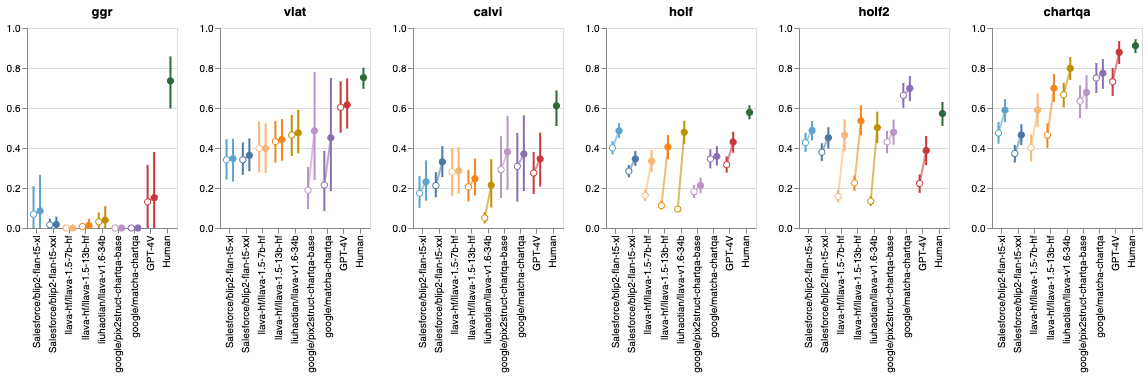

In [333]:
ci_df = ci_dfs[
    ((ci_dfs['scoring_type'] == 'valid_only') &
    (ci_dfs['agent_type'] == 'Human')) |
    (ci_dfs['agent_type'] != 'Human')
]


tests = ['ggr', 'vlat', 'calvi', 'holf', 'holf2',
       'chartqa-test-continuous-human']

plots = []
for test in tests:
    test_ci_df = ci_df[ci_df['test_type'] == test]
    if len(test) > 6:
        test = test[:7]
    
    plot = create_error_plot(test_ci_df, test)
    plot = plot.properties(width=150, height=200)
    plots.append(plot)

plots = alt.hconcat(*plots)
plots.save("./figures/human_machine_performance.pdf")
plots

In [347]:
# ci_df

## Check regression values

### Load R

In [335]:
%load_ext rpy2.ipython

In [336]:
%%R
install.packages("lme4")
library(lme4)

--- Please select a CRAN mirror for use in this session ---
Secure CRAN mirrors 

 1: 0-Cloud [https]
 2: Australia (Canberra) [https]
 3: Australia (Melbourne 1) [https]
 4: Australia (Melbourne 2) [https]
 5: Austria (Wien 1) [https]
 6: Belgium (Brussels) [https]
 7: Brazil (PR) [https]
 8: Brazil (SP 1) [https]
 9: Brazil (SP 2) [https]
10: Bulgaria [https]
11: Canada (MB) [https]
12: Canada (ON 1) [https]
13: Canada (ON 2) [https]
14: Chile (Santiago) [https]
15: China (Beijing 2) [https]
16: China (Beijing 3) [https]
17: China (Hefei) [https]
18: China (Hong Kong) [https]
19: China (Jinan) [https]
20: China (Lanzhou) [https]
21: China (Nanjing) [https]
22: China (Shanghai 2) [https]
23: China (Shenzhen) [https]
24: China (Wuhan) [https]
25: Colombia (Cali) [https]
26: Costa Rica [https]
27: Cyprus [https]
28: Czech Republic [https]
29: Denmark [https]
30: East Asia [https]
31: Ecuador (Cuenca) [https]
32: France (Lyon 1) [https]
33: France (Lyon 2) [https]
34: France (Paris 1) [h

Selection:  68



The downloaded binary packages are in
	/var/folders/v8/3zpbxkws53b3x6m8509jyml80000gn/T//RtmpgccFPA/downloaded_packages


trying URL 'https://cran.case.edu/bin/macosx/big-sur-arm64/contrib/4.4/lme4_1.1-36.tgz'
Content type 'application/x-gzip' length 7079300 bytes (6.8 MB)
downloaded 6.8 MB

Loading required package: Matrix
In addition: Warning message:
In doTryCatch(return(expr), name, parentenv, handler) :
  unable to load shared object '/Library/Frameworks/R.framework/Resources/modules//R_X11.so':
  dlopen(/Library/Frameworks/R.framework/Resources/modules//R_X11.so, 0x0006): Library not loaded: /opt/X11/lib/libSM.6.dylib
  Referenced from: <34C5A480-1AC4-30DF-83C9-30A913FC042E> /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/modules/R_X11.so
  Reason: tried: '/opt/X11/lib/libSM.6.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/X11/lib/libSM.6.dylib' (no such file), '/opt/X11/lib/libSM.6.dylib' (no such file), '/usr/local/lib/libSM.6.dylib' (no such file), '/usr/lib/libSM.6.dylib' (no such file, not in dyld cache)


### Regression Model

In [348]:
model_only_df = all_df[all_df['agent_type'] != 'Human']

In [352]:
%%R -i model_only_df

control <- glmerControl(
    optimizer = "bobyqa",
    optCtrl = list(maxfun = 2e5)
)

null_model <- glmer(
    is_correct ~ 1 + (1 | item_id), 
    data = model_only_df, 
    family = binomial, 
    control = control
)

### Do models reliably differ in overall performance from one another?

In [353]:
%%R -i model_only_df

agent_model <- glmer(
    is_correct ~ agent_type + (1 | item_id), 
    data = model_only_df, 
    family = binomial,
    control = control
)

anova(null_model, agent_model, test="LRT")

Data: model_only_df
Models:
null_model: is_correct ~ 1 + (1 | item_id)
agent_model: is_correct ~ agent_type + (1 | item_id)
            npar   AIC   BIC logLik deviance  Chisq Df Pr(>Chisq)    
null_model     2 43591 43608 -21793    43587                         
agent_model    9 42675 42753 -21329    42657 929.35  7  < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### Is human-model gap was smaller for misleading items in CALVI?

In [ ]:
calvi_df = 

## Difference of means

In [ ]:
def bootstrap_diff_of_mean_ci(
        data: pd.DataFrame,
        measure,
        id_col,
        n_iterations=1000,
        statistic=np.mean
    ):
    
    items = list(data[id_col].unique())
    n_size = len(items)
    df = data.copy()

    def bootstrap_iteration(data, chosen_items):
        filter_df = pd.concat(
            [data[data[id_col].isin([item])] for item in chosen_items]
        )
        
        bs_mean = statistic(filter_df[measure]) 
        return (bs_mean, list(chosen_items))

    
    qset_means1 = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df[df['modality'] == 'table'].copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )

    qset_means2 = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df[df['modality'] == 'graph'].copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )
    
    means = []
    qs_used = []
    means1 = [bs_mean for bs_mean, chosen_qs in qset_means1]
    means2 = [bs_mean for bs_mean, chosen_qs in qset_means2]
    means = np.subtract(means1, means2)
 
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper

def create_diff_of_mean_ci_df(
    data: pd.DataFrame,
    measure,
    id_col,
    statistic=np.mean
):
    """ create the dataframe for 95% bootstrapped confidence interval
    data: dataset
    measure: dependent variable
    id_col: units to bootstrap along (e.g. participant_d or item_id)
    condition_col: the different conditions of the experiments
    """
    
    data_list = []


    lower, upper = bootstrap_diff_of_mean_ci(data, measure=measure, statistic=statistic, id_col=id_col)
    mean1 = data[data['modality'] == 'table'][measure].mean()
    mean2 = data[data['modality'] == 'graph'][measure].mean()
    mean = mean1 - mean2
    
    data_list.append({
        "mean": mean,
        "ci_upper": upper, 
        "ci_lower": lower,
    })

    return pd.DataFrame(data_list)

In [ ]:
diff_of_mean_modality_ci_df = create_diff_of_mean_ci_df(
    mod_df[mod_df['test_type'] == 'brbf'],
    measure='is_correct',
    id_col='question_image',
)
diff_of_mean_modality_ci_df